# Flink Frozen Product Analysis


-----------

## Project Team

| No. | Team Member | Role |
|---:|---|---|
| 1 | Nisarg Padia | Data Collector |
| 2 | Aryan Sutariya | Data Analyst |
| 3 | Bhavik Devani | Business Analyst |
| 4 | Aksh Patel | Documentation |
| 5 | Shweta Ajudeeya | Project Coordinator |

---------------

## Roles and Responsibilities

### 1. Nisarg Padia — Data Collector
- Collect the data required for the project.
- Organise the collected data for the team.

### 2. Aryan Sutariya — Data Analyst
- Explore and analyse the available data.
- Identify patterns, trends, and useful findings.

### 3. Bhavik Devani — Business Analyst
- Connect the analysis with the business question.
- Interpret findings and develop practical business insights.

### 4. Aksh Patel — Documentation
- Maintain project notes and documentation.
- Record the methodology, analysis, and findings.

### 5. Shweta Ajudeeya — Project Coordinator
- Coordinate tasks and communication within the team.
- Help the team track progress and deadlines.

-------

# **-------------Part-1 : Nisarg Padia --------------**

## Step 1: Environment Setup & Library imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("Libraries imported successfully!")


Libraries imported successfully!


## Step 2: Data Extraction & Initial Inspection


In [2]:
FILE_PATH = "Flink_Frozen_Product_Data_October_2026.csv"

raw_df = pd.read_csv(FILE_PATH)

df = raw_df.copy()

print("DATA EXTRACTION COMPLETED")
print("-" * 50)
print("File:", FILE_PATH)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head(10))

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())


DATA EXTRACTION COMPLETED
--------------------------------------------------
File: Flink_Frozen_Product_Data_October_2026.csv
Total Rows: 1134
Total Columns: 21


,Product_ID,Product_Name,Category,Brand,Purchase_Cost,Selling_Price,Storage_Temperature_C,Batch_ID,Warehouse_ID,Purchase_Date,Expiry_Date,Initial_Stock,Quantity_Sold,Current_Stock,Expired_Quantity,Waste_Reason,Transaction_ID,Sale_Date,Unit_Selling_Price,Discount_Percentage,Total_Revenue
0,FP014,Garlic Bread,Bakery,BakeHouse,1.35,2.99,-18,FP014-B01,Berlin-Mitte,2026-09-28,2026-10-25,197,0.0,0,0,NaN,NaN,2026-10-27,2.99,0,0.00
1,FP014,Garlic Bread,Bakery,BakeHouse,1.35,2.99,-18,FP014-B02,Hamburg-Nord,2026-09-21,2026-10-30,207,6.0,79,0,NaN,TX202610230142,2026-10-23,2.84,5,17.04
2,FP009,Frozen Lasagne,icecream,CasaMeal,2.70,5.79,-18,FP009-B02,Hamburg-Nord,2026-09-11,2026-10-03,107,6.0,95,0,NaN,TX202610020092,2026-10-02,3.76,35,22.56
3,FP007,Vanilla Ice Cream,Ice Cream,SweetPeak,2.00,4.29,-18,FP007-B02,Berlin-Mitte,2026-09-08,2026-11-05,213,3.0,77,0,NaN,TX202610310072,2026-10-31,4.29,0,12.87
4,FP001,Frozen Margherita Pizza,Pizza,FrostBite,2.10,4.49,-18,FP001-B02,Heidelberg,2026-09-28,2026-09-28,186,3.0,143,0,NaN,TX202610060012,2026-10-06,4.49,0,13.47
5,FP010,Frozen Fries,Potatoes,GoldenFarm,1.10,2.59,-18,FP010-B01,Hamburg-Nord,2026-09-25,2026-12-05,86,12.0,39,0,NaN,TX202610040101,2026-10-04,2.59,0,31.08
6,FP012,Vegan Burger Patties,Plant Based,PlantGood,2.90,6.29,-18,FP012-B01,Hamburg-Nord,2026-09-27,2026-10-20,118,3.0,111,0,NaN,TX202610030121,2026-10-03,6.29,0,18.87
7,FP011,Frozen Salmon Fillets,Seafood,OceanWay,4.60,8.99,-18,FP011-B02,Munich-West,2026-09-15,2026-11-05,102,2.0,81,0,NaN,TX202610150112,2026-10-15,8.99,0,17.98
8,FP007,Vanilla Ice Cream,Ice Cream,SweetPeak,2.00,4.29,-18,FP007-B02,Berlin-Mitte,2026-09-08,2026-11-05,213,4.0,104,0,NaN,NaN,2026-10-25,4.29,0,17.16
9,FP016,Cheese Pizza Snacks,Pizza,FrostBite,2.25,4.79,-18,FP016-B02,Berlin-Mitte,2026-09-11,2026-10-30,136,6.0,27,0,NaN,TX202610210162,2026-10-21,4.79,0,28.74



Dataset Shape: (1134, 21)

Column Names:
['Product_ID', 'Product_Name', 'Category', 'Brand', 'Purchase_Cost', 'Selling_Price', 'Storage_Temperature_C', 'Batch_ID', 'Warehouse_ID', 'Purchase_Date', 'Expiry_Date', 'Initial_Stock', 'Quantity_Sold', 'Current_Stock', 'Expired_Quantity', 'Waste_Reason', 'Transaction_ID', 'Sale_Date', 'Unit_Selling_Price', 'Discount_Percentage', 'Total_Revenue']


## Step 3: Structural Data Inspection & Schema Profiling


In [3]:
df.info()

display(df.describe(include="all").T)

structure = pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Non_Null_Count": df.notnull().sum().values,
    "Missing_Count": df.isnull().sum().values,
    "Unique_Values": df.nunique().values
})

display(structure)


<class 'pandas.DataFrame'>
RangeIndex: 1134 entries, 0 to 1133
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Product_ID             1134 non-null   str    
 1   Product_Name           1134 non-null   str    
 2   Category               1134 non-null   str    
 3   Brand                  1121 non-null   str    
 4   Purchase_Cost          1125 non-null   float64
 5   Selling_Price          1134 non-null   float64
 6   Storage_Temperature_C  1134 non-null   int64  
 7   Batch_ID               1134 non-null   str    
 8   Warehouse_ID           1123 non-null   str    
 9   Purchase_Date          1134 non-null   str    
 10  Expiry_Date            1125 non-null   str    
 11  Initial_Stock          1134 non-null   int64  
 12  Quantity_Sold          1125 non-null   float64
 13  Current_Stock          1134 non-null   int64  
 14  Expired_Quantity       1134 non-null   int64  
 15  Waste_Reason   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_ID,1134,18,FP012,65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,1134,18,Vegan Burger Patties,65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1134,17,Pizza,192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,1121,15,FrostBite,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase_Cost,1125.0,NaN,NaN,NaN,2.538302,4.165789,0.95,1.35,2.25,2.8,79.4
Selling_Price,1134.0,NaN,NaN,NaN,4.858783,1.883251,2.29,2.99,4.79,5.99,8.99
Storage_Temperature_C,1134.0,NaN,NaN,NaN,-18.0,0.0,-18.0,-18.0,-18.0,-18.0,-18.0
Batch_ID,1134,36,FP006-B01,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Warehouse_ID,1123,4,Hamburg-Nord,313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase_Date,1134,19,2026-09-28,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Column_Name,Data_Type,Non_Null_Count,Missing_Count,Unique_Values
0,Product_ID,str,1134,0,18
1,Product_Name,str,1134,0,18
2,Category,str,1134,0,17
3,Brand,str,1121,13,15
4,Purchase_Cost,float64,1125,9,23
5,Selling_Price,float64,1134,0,18
6,Storage_Temperature_C,int64,1134,0,1
7,Batch_ID,str,1134,0,36
8,Warehouse_ID,str,1123,11,4
9,Purchase_Date,str,1134,0,19


## Step 4: Data Quality Assessment
Audit the dataset for common data engineering anomalies prior to cleaning:
1. **Missing Values:** Calculate missing counts and percentages per column.
2. **Exact Duplicates:** Identify identical rows (`14` duplicate records).
3. **Negative Quantities:** Check stock and sales volume columns for invalid negative numbers.
4. **Invalid Discounts:** Verify that `Discount_Percentage` falls strictly within `0%–100%`.
5. **Categorical Consistency:** Inspect unique values in `Category`, `Brand`, and `Warehouse_ID` for casing, whitespace, or spelling discrepancies.

In [4]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

print("MISSING VALUE REPORT")
display(missing_report)

print("Exact duplicate rows:", df.duplicated().sum())

quantity_columns = [
    "Initial_Stock",
    "Quantity_Sold",
    "Current_Stock",
    "Expired_Quantity"
]

print("\nNEGATIVE QUANTITY CHECK")

for column in quantity_columns:
    print(
        column,
        "Negative values:",
        (df[column] < 0).sum()
    )

print(
    "\nDiscount outside 0-100:",
    (~df["Discount_Percentage"].between(0, 100)).sum()
)

print("\nCATEGORY VALUES")
print(df["Category"].value_counts(dropna=False))

print("\nBRAND VALUES")
print(df["Brand"].value_counts(dropna=False))

print("\nWAREHOUSE VALUES")
print(df["Warehouse_ID"].value_counts(dropna=False))


MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
Waste_Reason,1110,97.88
Transaction_ID,588,51.85
Brand,13,1.15
Warehouse_ID,11,0.97
Purchase_Cost,9,0.79
Quantity_Sold,9,0.79
Expiry_Date,9,0.79
Product_ID,0,0.00
Category,0,0.00
Product_Name,0,0.00


Exact duplicate rows: 14

NEGATIVE QUANTITY CHECK
Initial_Stock Negative values: 0
Quantity_Sold Negative values: 8
Current_Stock Negative values: 0
Expired_Quantity Negative values: 0

Discount outside 0-100: 4

CATEGORY VALUES
Category
Pizza                192
Seafood              187
Vegetables           181
Ice Cream            118
Fruit                 61
Meat                  61
Bakery                60
Plant Based           60
Breakfast             60
Ready Meals           60
Potatoes              59
icecream               9
pizza                  7
Frozen vegetables      7
PIZZA                  6
Sea Food               5
vegetables             1
Name: count, dtype: int64

BRAND VALUES
Brand
FrostBite      188
OceanWay       181
GreenFarm      181
SweetPeak      120
PlantGood       65
BakeHouse       63
CasaMeal        62
GoldenFarm      61
MorningJoy      61
BerryBest       60
CrispyCo        59
NaN             13
OCEANWAY         8
frostbite        4
Sweet Peak       4
Green 

## Step 5: Duplicate Record Removal
Drop exact duplicate rows (`14` records removed, leaving `1,120` unique records) while preserving the first occurrence, and reset the DataFrame index.

In [5]:
before_removal = len(df)

df = df.drop_duplicates(keep="first").copy()

after_removal = len(df)

removed_records = before_removal - after_removal

print("DUPLICATE REMOVAL COMPLETED")
print("Original Records:", before_removal)
print("Remaining Records:", after_removal)
print("Duplicates Removed:", removed_records)

df.reset_index(drop=True, inplace=True)


DUPLICATE REMOVAL COMPLETED
Original Records: 1134
Remaining Records: 1120
Duplicates Removed: 14


C:\Users\scpco\AppData\Local\Temp\ipykernel_17068\819859012.py:14: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


## Step 7: Data Type Conversion


In [6]:
date_columns = [
    "Purchase_Date",
    "Expiry_Date",
    "Sale_Date"
]

numeric_columns = [
    "Purchase_Cost",
    "Selling_Price",
    "Storage_Temperature_C",
    "Initial_Stock",
    "Quantity_Sold",
    "Current_Stock",
    "Expired_Quantity",
    "Unit_Selling_Price",
    "Discount_Percentage",
    "Total_Revenue"
]

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column],
        errors="coerce"
    )

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("DATA TYPE CONVERSION COMPLETED")

print(df.dtypes)


DATA TYPE CONVERSION COMPLETED
Product_ID                          str
Product_Name                        str
Category                            str
Brand                               str
Purchase_Cost                   float64
Selling_Price                   float64
Storage_Temperature_C             int64
Batch_ID                            str
Warehouse_ID                        str
Purchase_Date            datetime64[us]
Expiry_Date              datetime64[us]
Initial_Stock                     int64
Quantity_Sold                   float64
Current_Stock                     int64
Expired_Quantity                  int64
Waste_Reason                        str
Transaction_ID                      str
Sale_Date                datetime64[us]
Unit_Selling_Price              float64
Discount_Percentage               int64
Total_Revenue                   float64
dtype: object


## Step 8: Missing Value Flagging (Non-Destructive Handling)


In [7]:
missing_before = df.isnull().sum()

print("MISSING VALUES BEFORE HANDLING")
display(missing_before[missing_before > 0])


important_columns = [
    "Brand",
    "Purchase_Cost",
    "Warehouse_ID",
    "Expiry_Date",
    "Quantity_Sold",
    "Transaction_ID"
]

for column in important_columns:
    df[column + "_Missing"] = df[column].isnull()

print("\nMISSING VALUE FLAGS CREATED")

display(
    df[
        [c + "_Missing" for c in important_columns]
    ].head()
)


MISSING VALUES BEFORE HANDLING


Brand               13
Purchase_Cost        9
Warehouse_ID        11
Expiry_Date         16
Quantity_Sold        9
Waste_Reason      1096
Transaction_ID     580
dtype: int64


MISSING VALUE FLAGS CREATED


,Brand_Missing,Purchase_Cost_Missing,Warehouse_ID_Missing,Expiry_Date_Missing,Quantity_Sold_Missing,Transaction_ID_Missing
0,False,False,False,False,False,True
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False


## Step 9: Business Rule Validation & Outlier Detection


In [8]:
df["Invalid_Quantity"] = df["Quantity_Sold"] < 0

df["Invalid_Discount"] = (
    ~df["Discount_Percentage"].between(0, 100)
)

df["Invalid_Purchase_Cost"] = df["Purchase_Cost"] <= 0

df["Invalid_Selling_Price"] = (
    df["Selling_Price"] <= 0
)

df["Invalid_Date_Order"] = (
    df["Expiry_Date"] < df["Purchase_Date"]
)

df["Sale_After_Expiry"] = (
    df["Sale_Date"] > df["Expiry_Date"]
)

expected_revenue = (
    df["Quantity_Sold"] *
    df["Unit_Selling_Price"]
)

df["Revenue_Mismatch"] = (
    (df["Total_Revenue"] - expected_revenue).abs() > 0.01
)

df["Missing_Transaction_Flag"] = (
    df["Transaction_ID"].isnull()
)

Q1 = df["Purchase_Cost"].quantile(0.25)
Q3 = df["Purchase_Cost"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df["Purchase_Cost_Outlier"] = (
    (df["Purchase_Cost"] < lower_limit) |
    (df["Purchase_Cost"] > upper_limit)
)

validation_columns = [
    "Invalid_Quantity",
    "Invalid_Discount",
    "Invalid_Purchase_Cost",
    "Invalid_Selling_Price",
    "Invalid_Date_Order",
    "Sale_After_Expiry",
    "Revenue_Mismatch",
    "Missing_Transaction_Flag",
    "Purchase_Cost_Outlier"
]

validation_report = pd.DataFrame({
    "Issue": validation_columns,
    "Affected_Records": [
        int(df[column].sum())
        for column in validation_columns
    ]
})

print("BUSINESS RULE VALIDATION REPORT")
display(validation_report)


BUSINESS RULE VALIDATION REPORT


,Issue,Affected_Records
0,Invalid_Quantity,8
1,Invalid_Discount,4
2,Invalid_Purchase_Cost,0
3,Invalid_Selling_Price,0
4,Invalid_Date_Order,0
5,Sale_After_Expiry,550
6,Revenue_Mismatch,8
7,Missing_Transaction_Flag,580
8,Purchase_Cost_Outlier,5


## Step 10: Data Quality Scoring & Status Assignment


In [9]:
critical_flags = [
    "Invalid_Quantity",
    "Invalid_Discount",
    "Invalid_Purchase_Cost",
    "Invalid_Selling_Price",
    "Invalid_Date_Order",
    "Revenue_Mismatch"
]

df["Quality_Issue_Count"] = (
    df[critical_flags].sum(axis=1)
)

df["Data_Quality_Status"] = np.where(
    df["Quality_Issue_Count"] > 0,
    "Needs Review",
    "Passed"
)

print("DATA QUALITY STATUS")
print(df["Data_Quality_Status"].value_counts())

display(
    df[
        ["Product_ID", "Batch_ID",
         "Transaction_ID", "Quality_Issue_Count",
         "Data_Quality_Status"]
    ].head(20)
)


DATA QUALITY STATUS
Data_Quality_Status
Passed          1108
Needs Review      12
Name: count, dtype: int64


,Product_ID,Batch_ID,Transaction_ID,Quality_Issue_Count,Data_Quality_Status
0,FP014,FP014-B01,NaN,0,Passed
1,FP014,FP014-B02,TX202610230142,0,Passed
2,FP009,FP009-B02,TX202610020092,0,Passed
3,FP007,FP007-B02,TX202610310072,0,Passed
4,FP001,FP001-B02,TX202610060012,0,Passed
5,FP010,FP010-B01,TX202610040101,0,Passed
6,FP012,FP012-B01,TX202610030121,0,Passed
7,FP011,FP011-B02,TX202610150112,0,Passed
8,FP007,FP007-B02,NaN,0,Passed
9,FP016,FP016-B02,TX202610210162,0,Passed


## Step 11: Dataset Partitioning (Clean vs. Review Queues)


In [10]:
clean_df = df[
    df["Data_Quality_Status"] == "Passed"
].copy()

review_df = df[
    df["Data_Quality_Status"] == "Needs Review"
].copy()

print("DATA SEPARATION COMPLETED")
print("-" * 40)

print("Total Processed Records:", len(df))
print("Passed Records:", len(clean_df))
print("Records Requiring Review:", len(review_df))

print("\nCLEAN DATA PREVIEW")
display(clean_df.head())

print("\nREVIEW DATA PREVIEW")
display(review_df.head())


DATA SEPARATION COMPLETED
----------------------------------------
Total Processed Records: 1120
Passed Records: 1108
Records Requiring Review: 12

CLEAN DATA PREVIEW


,Product_ID,Product_Name,Category,Brand,Purchase_Cost,Selling_Price,Storage_Temperature_C,Batch_ID,Warehouse_ID,Purchase_Date,Expiry_Date,Initial_Stock,Quantity_Sold,Current_Stock,Expired_Quantity,Waste_Reason,Transaction_ID,Sale_Date,Unit_Selling_Price,Discount_Percentage,Total_Revenue,Brand_Missing,Purchase_Cost_Missing,Warehouse_ID_Missing,Expiry_Date_Missing,Quantity_Sold_Missing,Transaction_ID_Missing,Invalid_Quantity,Invalid_Discount,Invalid_Purchase_Cost,Invalid_Selling_Price,Invalid_Date_Order,Sale_After_Expiry,Revenue_Mismatch,Missing_Transaction_Flag,Purchase_Cost_Outlier,Quality_Issue_Count,Data_Quality_Status
0,FP014,Garlic Bread,Bakery,BakeHouse,1.35,2.99,-18,FP014-B01,Berlin-Mitte,2026-09-28,2026-10-25,197,0.0,0,0,NaN,NaN,2026-10-27,2.99,0,0.00,False,False,False,False,False,True,False,False,False,False,False,True,False,True,False,0,Passed
1,FP014,Garlic Bread,Bakery,BakeHouse,1.35,2.99,-18,FP014-B02,Hamburg-Nord,2026-09-21,2026-10-30,207,6.0,79,0,NaN,TX202610230142,2026-10-23,2.84,5,17.04,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,0,Passed
2,FP009,Frozen Lasagne,icecream,CasaMeal,2.70,5.79,-18,FP009-B02,Hamburg-Nord,2026-09-11,2026-10-03,107,6.0,95,0,NaN,TX202610020092,2026-10-02,3.76,35,22.56,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,0,Passed
3,FP007,Vanilla Ice Cream,Ice Cream,SweetPeak,2.00,4.29,-18,FP007-B02,Berlin-Mitte,2026-09-08,2026-11-05,213,3.0,77,0,NaN,TX202610310072,2026-10-31,4.29,0,12.87,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,0,Passed
4,FP001,Frozen Margherita Pizza,Pizza,FrostBite,2.10,4.49,-18,FP001-B02,Heidelberg,2026-09-28,2026-09-28,186,3.0,143,0,NaN,TX202610060012,2026-10-06,4.49,0,13.47,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,0,Passed



REVIEW DATA PREVIEW


,Product_ID,Product_Name,Category,Brand,Purchase_Cost,Selling_Price,Storage_Temperature_C,Batch_ID,Warehouse_ID,Purchase_Date,Expiry_Date,Initial_Stock,Quantity_Sold,Current_Stock,Expired_Quantity,Waste_Reason,Transaction_ID,Sale_Date,Unit_Selling_Price,Discount_Percentage,Total_Revenue,Brand_Missing,Purchase_Cost_Missing,Warehouse_ID_Missing,Expiry_Date_Missing,Quantity_Sold_Missing,Transaction_ID_Missing,Invalid_Quantity,Invalid_Discount,Invalid_Purchase_Cost,Invalid_Selling_Price,Invalid_Date_Order,Sale_After_Expiry,Revenue_Mismatch,Missing_Transaction_Flag,Purchase_Cost_Outlier,Quality_Issue_Count,Data_Quality_Status
82,FP005,Chicken Nuggets,Meat,CrispyCo,3.20,6.49,-18,FP005-B01,Heidelberg,2026-09-17,2026-10-15,103,-2.0,0,0,NaN,NaN,2026-10-19,6.49,0,0.00,False,False,False,False,False,True,True,False,False,False,False,True,True,True,False,2,Needs Review
270,FP007,Vanilla Ice Cream,Ice Cream,SweetPeak,2.00,4.29,-18,FP007-B02,Berlin-Mitte,2026-09-08,2026-11-05,213,-4.0,148,0,NaN,TX202610150072,2026-10-15,4.29,0,38.61,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,2,Needs Review
383,FP008,Strawberry Ice Cream,Ice Cream,SweetPeak,2.15,4.59,-18,FP008-B02,Berlin-Mitte,2026-09-09,2026-10-15,209,-4.0,0,0,NaN,NaN,2026-10-17,4.59,0,0.00,False,False,False,False,False,True,True,False,False,False,False,True,True,True,False,2,Needs Review
418,FP004,Frozen Broccoli,Vegetables,frostbite,1.05,2.49,-18,FP004-B02,Hamburg-Nord,2026-09-18,2026-10-20,100,-2.0,0,0,NaN,NaN,2026-10-23,2.49,0,0.00,False,False,False,False,False,True,True,False,False,False,False,True,True,True,False,2,Needs Review
442,FP015,Frozen Waffles,Breakfast,MorningJoy,1.70,3.79,-18,FP015-B01,Hamburg-Nord,2026-09-24,2026-10-25,168,-2.0,132,0,NaN,NaN,2026-10-12,3.79,0,0.00,False,False,False,False,False,True,True,False,False,False,False,False,True,True,False,2,Needs Review


## Step 12: Final Data Quality Audit Summary


In [11]:
quality_report = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Original Columns",
        "Exact Duplicates Removed",
        "Processed Records",
        "Clean Records",
        "Records Requiring Review",
        "Missing Brand",
        "Missing Purchase Cost",
        "Missing Warehouse",
        "Missing Expiry Date",
        "Missing Quantity Sold",
        "Missing Transaction ID",
        "Negative Quantities",
        "Invalid Discounts",
        "Revenue Mismatches",
        "Sales After Expiry"
    ],

    "Value": [
        len(raw_df),
        len(raw_df.columns),
        len(raw_df) - len(raw_df.drop_duplicates()),
        len(df),
        len(clean_df),
        len(review_df),
        int(df["Brand"].isnull().sum()),
        int(df["Purchase_Cost"].isnull().sum()),
        int(df["Warehouse_ID"].isnull().sum()),
        int(df["Expiry_Date"].isnull().sum()),
        int(df["Quantity_Sold"].isnull().sum()),
        int(df["Transaction_ID"].isnull().sum()),
        int(df["Invalid_Quantity"].sum()),
        int(df["Invalid_Discount"].sum()),
        int(df["Revenue_Mismatch"].sum()),
        int(df["Sale_After_Expiry"].sum())
    ]
})

print("FINAL DATA QUALITY REPORT")
display(quality_report)


FINAL DATA QUALITY REPORT


,Metric,Value
0,Original Records,1134
1,Original Columns,21
2,Exact Duplicates Removed,14
3,Processed Records,1120
4,Clean Records,1108
5,Records Requiring Review,12
6,Missing Brand,13
7,Missing Purchase Cost,9
8,Missing Warehouse,11
9,Missing Expiry Date,16


## Step 13: Export Processed Artifacts


In [12]:
OUTPUT_FOLDER = Path("Flink_Preprocessing_Output")

OUTPUT_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FOLDER / "Flink_Processed_Full_Data.csv",
    index=False
)

clean_df.to_csv(
    OUTPUT_FOLDER / "Flink_Clean_Data.csv",
    index=False
)

review_df.to_csv(
    OUTPUT_FOLDER / "Flink_Review_Required.csv",
    index=False
)

quality_report.to_csv(
    OUTPUT_FOLDER / "Flink_Data_Quality_Report.csv",
    index=False
)

print("ALL FILES EXPORTED SUCCESSFULLY")
print("\nOutput Files:")

for file in OUTPUT_FOLDER.iterdir():
    print(file.name)


ALL FILES EXPORTED SUCCESSFULLY

Output Files:
Flink_Clean_Data.csv
Flink_Data_Quality_Report.csv
Flink_Processed_Full_Data.csv
Flink_Review_Required.csv


## Step 14: Post-Export Integrity Verification


In [13]:
final_file = (
    OUTPUT_FOLDER / "Flink_Processed_Full_Data.csv"
)

verified_df = pd.read_csv(final_file)

print("FINAL VERIFICATION")
print("-" * 40)

print("Original Dataset:", raw_df.shape)
print("Processed Dataset:", df.shape)
print("Exported Dataset:", verified_df.shape)

assert len(verified_df) == len(df), (
    "Record count mismatch!"
)

assert list(verified_df.columns) == list(df.columns), (
    "Column mismatch!"
)

print("\nSUCCESS: DATA EXTRACTION AND EXPORT VERIFIED!")


FINAL VERIFICATION
----------------------------------------
Original Dataset: (1134, 21)
Processed Dataset: (1120, 38)
Exported Dataset: (1120, 38)

SUCCESS: DATA EXTRACTION AND EXPORT VERIFIED!


---
# **-------------Part-2 : Aryan Sutariya --------------**

## Investigation Blueprint
* **Main Question:** How can Flink reduce frozen food waste and improve profitability?
* **Descriptive Question:** Which products expire most, and what are the monthly losses?
* **Diagnostic Question:** Why do these products expire before being sold?
* **Recommendation Question:** What stock and discount strategies can reduce expiry and financial losses?

## Step 15: Load Clean Dataset & Engineer Financial & Shelf-Life Metrics

In [14]:
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

clean_file = Path("Flink_Preprocessing_Output/Flink_Clean_Data.csv")
if clean_file.exists():
    eda_df = pd.read_csv(clean_file)
    for col in ["Purchase_Date", "Expiry_Date", "Sale_Date"]:
        eda_df[col] = pd.to_datetime(eda_df[col], errors="coerce")
elif "clean_df" in globals():
    eda_df = clean_df.copy()
else:
    eda_df = df[df["Data_Quality_Status"] == "Passed"].copy()

eda_df["Unit_Margin"] = eda_df["Unit_Selling_Price"] - eda_df["Purchase_Cost"]
eda_df["COGS_Sold"] = eda_df["Quantity_Sold"] * eda_df["Purchase_Cost"]
eda_df["Gross_Profit"] = eda_df["Total_Revenue"] - eda_df["COGS_Sold"]
eda_df["Expired_Loss_EUR"] = eda_df["Expired_Quantity"] * eda_df["Purchase_Cost"]
eda_df["Net_Profit_After_Waste"] = eda_df["Gross_Profit"] - eda_df["Expired_Loss_EUR"]
eda_df["Shelf_Life_Days"] = (eda_df["Expiry_Date"] - eda_df["Purchase_Date"]).dt.days
eda_df["Days_to_Expiry_at_Sale"] = (eda_df["Expiry_Date"] - eda_df["Sale_Date"]).dt.days
eda_df["Is_Discounted"] = eda_df["Discount_Percentage"] > 0
eda_df["Sale_Month"] = eda_df["Sale_Date"].dt.to_period("M").astype(str)

print("DATA ANALYST DATASET READY")
print("-" * 50)
print("Records Loaded:", len(eda_df))
print("Unique Products:", eda_df["Product_ID"].nunique())
print("Unique Batches:", eda_df["Batch_ID"].nunique())
print("Warehouses:", eda_df["Warehouse_ID"].dropna().unique().tolist())
display(eda_df[["Product_ID", "Product_Name", "Category", "Batch_ID", "Expired_Quantity", "Expired_Loss_EUR", "Total_Revenue", "Gross_Profit", "Net_Profit_After_Waste"]].head(10))


DATA ANALYST DATASET READY
--------------------------------------------------
Records Loaded: 1108
Unique Products: 18
Unique Batches: 36
Warehouses: ['Berlin-Mitte', 'Hamburg-Nord', 'Heidelberg', 'Munich-West']


,Product_ID,Product_Name,Category,Batch_ID,Expired_Quantity,Expired_Loss_EUR,Total_Revenue,Gross_Profit,Net_Profit_After_Waste
0,FP014,Garlic Bread,Bakery,FP014-B01,0,0.0,0.00,0.00,0.00
1,FP014,Garlic Bread,Bakery,FP014-B02,0,0.0,17.04,8.94,8.94
2,FP009,Frozen Lasagne,icecream,FP009-B02,0,0.0,22.56,6.36,6.36
3,FP007,Vanilla Ice Cream,Ice Cream,FP007-B02,0,0.0,12.87,6.87,6.87
4,FP001,Frozen Margherita Pizza,Pizza,FP001-B02,0,0.0,13.47,7.17,7.17
5,FP010,Frozen Fries,Potatoes,FP010-B01,0,0.0,31.08,17.88,17.88
6,FP012,Vegan Burger Patties,Plant Based,FP012-B01,0,0.0,18.87,10.17,10.17
7,FP011,Frozen Salmon Fillets,Seafood,FP011-B02,0,0.0,17.98,8.78,8.78
8,FP007,Vanilla Ice Cream,Ice Cream,FP007-B02,0,0.0,17.16,9.16,9.16
9,FP016,Cheese Pizza Snacks,Pizza,FP016-B02,0,0.0,28.74,15.24,15.24


## Step 16: Exploratory Data Analysis (EDA) — Portfolio KPI Overview & Distributions


EXECUTIVE PORTFOLIO & WASTE KPI SUMMARY (OCTOBER 2026)


,KPI_Metric,Value
0,Total Initial Stock Procured (Units),15235.00
1,Total Units Sold,2708.00
2,Total Expired Units (Waste),1913.00
3,Overall Portfolio Expiry Rate (%),12.56
4,Total Sales Revenue (EUR),11552.27
5,Gross Profit Before Waste (EUR),5097.22
6,Direct Financial Loss from Expiry (EUR),4284.60
7,Net Profit After Waste (EUR),812.62
8,Profit Erosion from Expiry (%),84.06


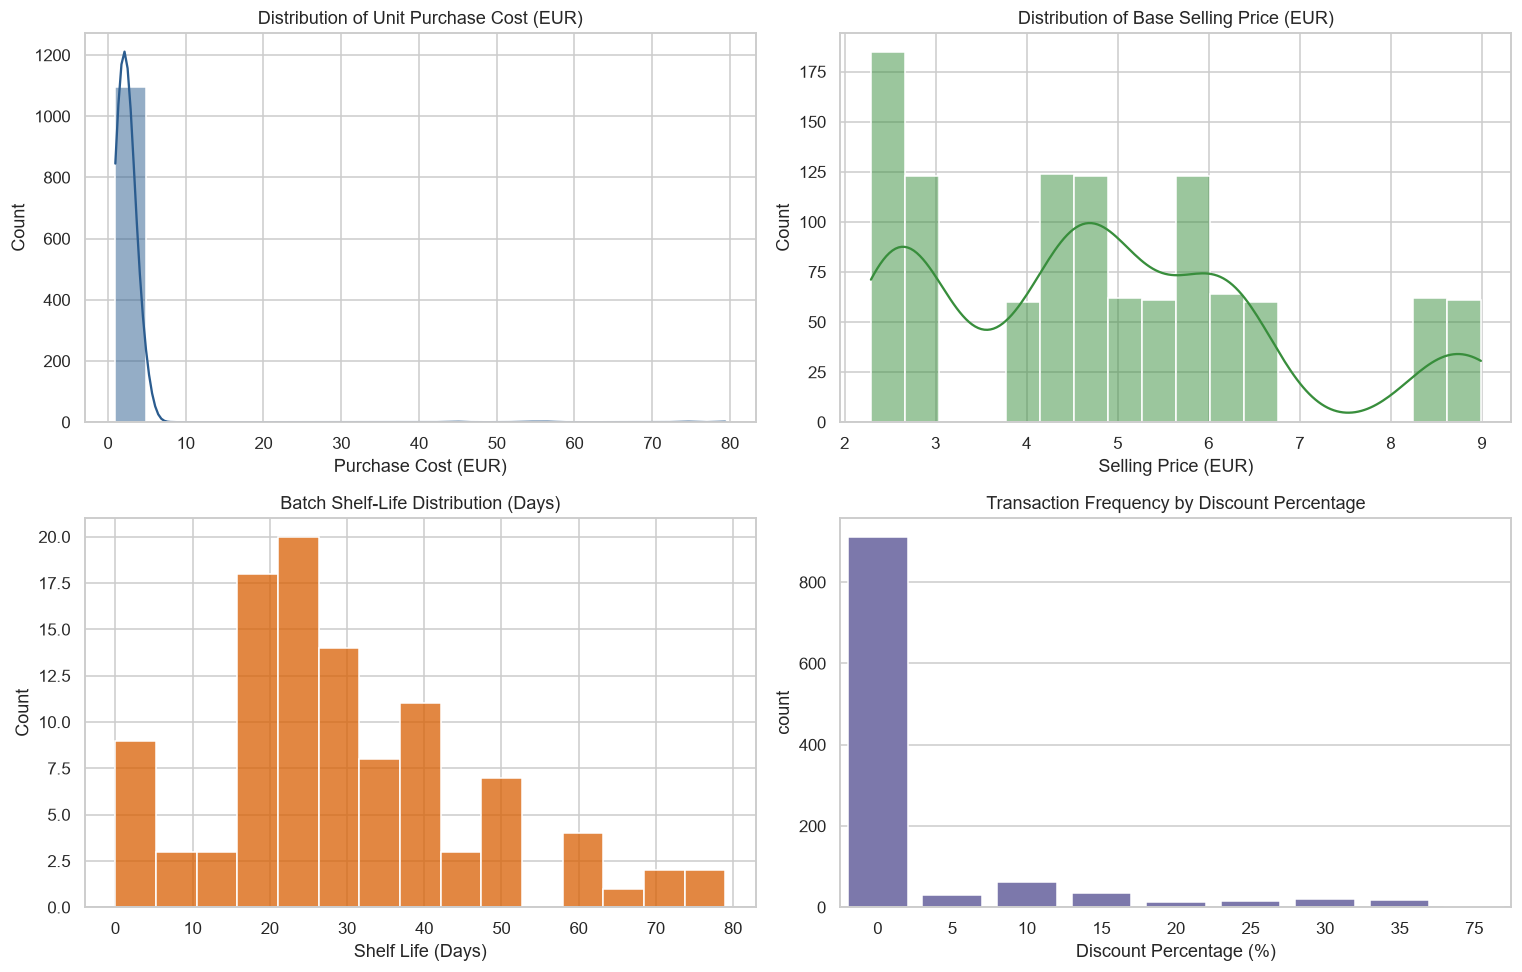

In [15]:
batch_level_df = (
    eda_df.groupby(["Batch_ID", "Product_ID", "Product_Name", "Category", "Brand", "Warehouse_ID"], dropna=False)
    .agg(
        Purchase_Cost=("Purchase_Cost", "first"),
        Selling_Price=("Selling_Price", "first"),
        Shelf_Life_Days=("Shelf_Life_Days", "first"),
        Initial_Stock=("Initial_Stock", "first"),
        Total_Units_Sold=("Quantity_Sold", "sum"),
        Ending_Stock=("Current_Stock", "min"),
        Total_Expired_Units=("Expired_Quantity", "sum"),
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Avg_Discount_Pct=("Discount_Percentage", "mean"),
        Max_Discount_Pct=("Discount_Percentage", "max"),
        Discounted_Tx_Count=("Is_Discounted", "sum"),
        Total_Tx_Count=("Product_ID", "count")
    )
    .reset_index()
)

batch_level_df["Net_Profit_After_Waste"] = batch_level_df["Gross_Profit"] - batch_level_df["Expired_Loss_EUR"]
batch_level_df["Sell_Through_Rate_Pct"] = (batch_level_df["Total_Units_Sold"] / batch_level_df["Initial_Stock"] * 100).round(2)
batch_level_df["Expiry_Waste_Rate_Pct"] = (batch_level_df["Total_Expired_Units"] / batch_level_df["Initial_Stock"] * 100).round(2)

kpi_summary = pd.DataFrame({
    "KPI_Metric": [
        "Total Initial Stock Procured (Units)",
        "Total Units Sold",
        "Total Expired Units (Waste)",
        "Overall Portfolio Expiry Rate (%)",
        "Total Sales Revenue (EUR)",
        "Gross Profit Before Waste (EUR)",
        "Direct Financial Loss from Expiry (EUR)",
        "Net Profit After Waste (EUR)",
        "Profit Erosion from Expiry (%)"
    ],
    "Value": [
        int(batch_level_df["Initial_Stock"].sum()),
        int(batch_level_df["Total_Units_Sold"].sum()),
        int(batch_level_df["Total_Expired_Units"].sum()),
        round(batch_level_df["Total_Expired_Units"].sum() / batch_level_df["Initial_Stock"].sum() * 100, 2),
        round(batch_level_df["Total_Revenue"].sum(), 2),
        round(batch_level_df["Gross_Profit"].sum(), 2),
        round(batch_level_df["Expired_Loss_EUR"].sum(), 2),
        round(batch_level_df["Net_Profit_After_Waste"].sum(), 2),
        round(batch_level_df["Expired_Loss_EUR"].sum() / batch_level_df["Gross_Profit"].sum() * 100, 2)
    ]
})

print("EXECUTIVE PORTFOLIO & WASTE KPI SUMMARY (OCTOBER 2026)")
display(kpi_summary)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(eda_df["Purchase_Cost"].dropna(), bins=20, kde=True, ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("Distribution of Unit Purchase Cost (EUR)")
axes[0, 0].set_xlabel("Purchase Cost (EUR)")

sns.histplot(eda_df["Selling_Price"].dropna(), bins=18, kde=True, ax=axes[0, 1], color="#388e3c")
axes[0, 1].set_title("Distribution of Base Selling Price (EUR)")
axes[0, 1].set_xlabel("Selling Price (EUR)")

sns.histplot(batch_level_df["Shelf_Life_Days"].dropna(), bins=15, kde=False, ax=axes[1, 0], color="#d95f02")
axes[1, 0].set_title("Batch Shelf-Life Distribution (Days)")
axes[1, 0].set_xlabel("Shelf Life (Days)")

sns.countplot(x="Discount_Percentage", data=eda_df, ax=axes[1, 1], color="#7570b3")
axes[1, 1].set_title("Transaction Frequency by Discount Percentage")
axes[1, 1].set_xlabel("Discount Percentage (%)")

plt.tight_layout()
plt.show()


## Step 17: Descriptive Analysis — Which Products Expire Most, and What Are the Monthly Losses?


PRODUCT EXPIRY & FINANCIAL LOSS RANKING (SORTED BY EUR LOSS)


,Product_ID,Product_Name,Category,Brand,Batches,Initial_Stock,Units_Sold,Expired_Units,Total_Revenue,Gross_Profit,Expired_Loss_EUR,Net_Profit_After_Waste,Avg_Shelf_Life_Days,Avg_Discount_Pct,Expiry_Rate_Pct,Sell_Through_Pct,Share_of_Total_Loss_Pct
0,FP017,Frozen Shrimp,Seafood,OceanWay,2,202,14.0,188,88.72,31.32,770.80,-739.48,19.500000,3.637931,93.07,6.93,17.99
1,FP008,Strawberry Ice Cream,Ice Cream,SweetPeak,3,617,55.0,344,223.47,102.78,739.60,-636.82,30.666667,3.525641,55.75,8.91,17.26
2,FP009,Frozen Lasagne,Ready Meals,CasaMeal,2,268,24.0,238,114.31,49.51,642.60,-593.09,13.000000,1.833333,88.81,8.96,15.00
3,FP012,Vegan Burger Patties,Plant Based,PlantGood,2,246,99.0,139,591.93,304.83,403.10,-98.27,22.500000,3.896552,56.50,40.24,9.41
4,FP006,Frozen Fish Fingers,Seafood,OceanWay,3,440,129.0,131,722.61,361.41,366.80,-5.39,38.333333,2.688834,29.77,29.32,8.56
5,FP015,Frozen Waffles,Breakfast,MorningJoy,3,478,130.0,184,461.16,-50.28,312.80,-363.08,30.333333,2.500000,38.49,27.20,7.30
6,FP002,Frozen Pepperoni Pizza,Pizza,FrostBite,4,554,150.0,123,718.43,350.93,301.35,49.58,21.500000,2.946839,22.20,27.08,7.03
7,FP018,Spinach Portions,Vegetables,GreenFarm,2,328,137.0,174,295.77,165.62,165.30,0.32,10.000000,3.892082,53.05,41.77,3.86
8,FP003,Frozen Mixed Vegetables,Frozen vegetables,GreenFarm,1,128,10.0,99,23.70,11.70,118.80,-107.10,26.000000,7.500000,77.34,7.81,2.77
9,FP014,Garlic Bread,Bakery,BakeHouse,3,601,284.0,84,814.96,431.56,113.40,318.16,31.000000,2.337849,13.98,47.25,2.65



CATEGORY-LEVEL EXPIRY & PROFITABILITY SUMMARY


,Category,SKUs,Initial_Stock,Units_Sold,Expired_Units,Total_Revenue,Gross_Profit,Expired_Loss_EUR,Net_Profit_After_Waste,Expiry_Rate_Pct
12,Seafood,10,1890,243.0,319,1703.58,677.38,1137.60,-460.22,16.88
4,Ice Cream,7,2135,246.0,344,1067.37,237.36,739.60,-502.24,16.11
10,Ready Meals,1,268,24.0,238,114.31,49.51,642.60,-593.09,88.81
8,Plant Based,1,246,99.0,139,591.93,304.83,403.10,-98.27,56.50
1,Breakfast,2,646,135.0,184,475.36,-44.58,312.80,-357.38,28.48
7,Pizza,7,1838,726.0,123,3371.90,1705.29,301.35,1403.94,6.69
13,Vegetables,9,1626,406.0,243,1008.06,550.03,237.75,312.28,14.94
2,Frozen vegetables,5,676,17.0,99,62.73,32.83,118.80,-85.97,14.64
0,Bakery,1,601,284.0,84,814.96,431.56,113.40,318.16,13.98
16,vegetables,1,137,7.0,45,26.18,9.38,108.00,-98.62,32.85



MONTHLY FINANCIAL & WASTE LOSS SUMMARY


,Sale_Month,Total_Revenue,Gross_Profit,Expired_Units,Expired_Loss_EUR,Net_Profit_After_Waste
0,2026-10,11552.27,5097.22,1913,4284.6,812.62



WEEKLY FINANCIAL & WASTE LOSS BREAKDOWN (OCTOBER 2026)


,Sale_Week,Total_Revenue,Gross_Profit,Expired_Units,Expired_Loss_EUR,Net_Profit_After_Waste
0,2026-09-28/2026-10-04,2769.82,1414.49,594,1604.65,-190.16
1,2026-10-05/2026-10-11,3643.22,1875.80,575,1031.45,844.35
2,2026-10-12/2026-10-18,2869.99,1116.36,317,672.55,443.81
3,2026-10-19/2026-10-25,1522.49,471.37,347,821.90,-350.53
4,2026-10-26/2026-11-01,746.75,219.20,80,154.05,65.15


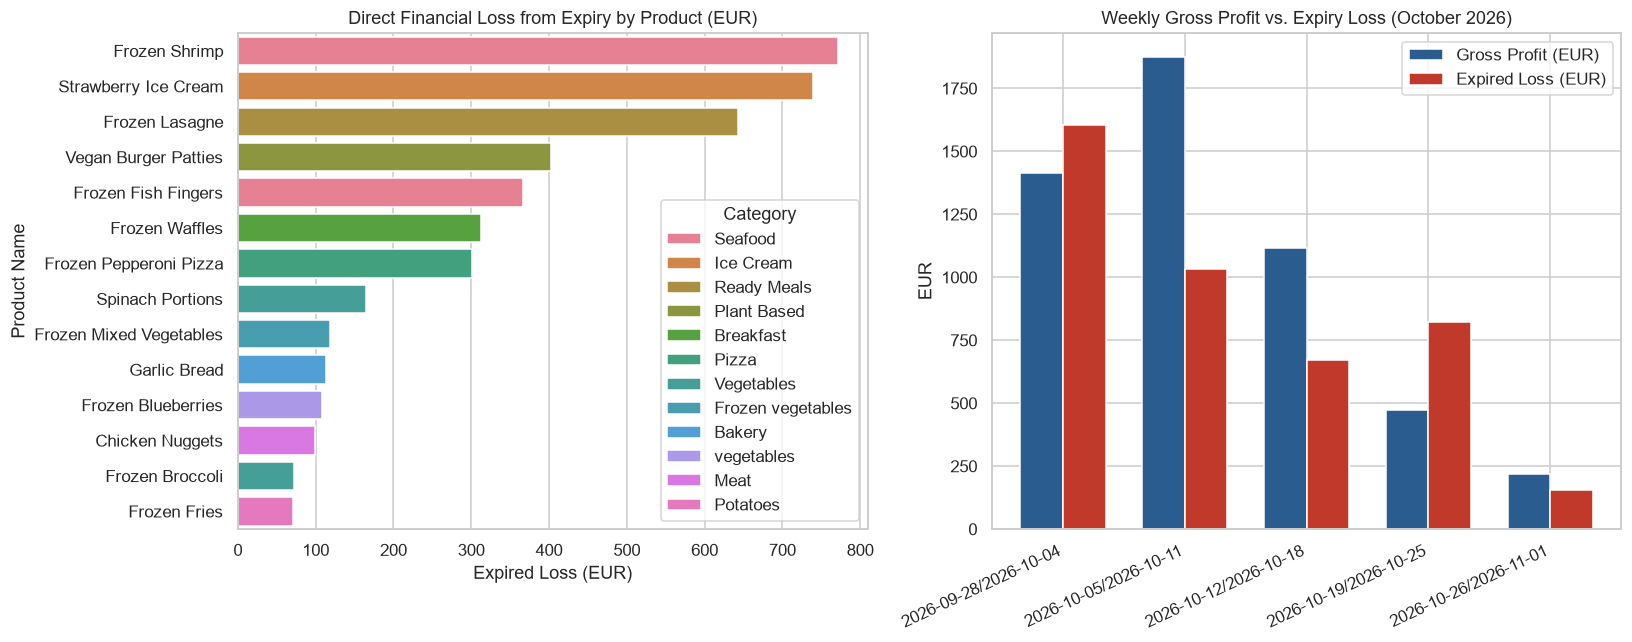

In [16]:
product_waste_summary = (
    batch_level_df.groupby(["Product_ID", "Product_Name", "Category", "Brand"], dropna=False)
    .agg(
        Batches=("Batch_ID", "count"),
        Initial_Stock=("Initial_Stock", "sum"),
        Units_Sold=("Total_Units_Sold", "sum"),
        Expired_Units=("Total_Expired_Units", "sum"),
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Net_Profit_After_Waste=("Net_Profit_After_Waste", "sum"),
        Avg_Shelf_Life_Days=("Shelf_Life_Days", "mean"),
        Avg_Discount_Pct=("Avg_Discount_Pct", "mean")
    )
    .reset_index()
)

product_waste_summary["Expiry_Rate_Pct"] = (
    product_waste_summary["Expired_Units"] / product_waste_summary["Initial_Stock"] * 100
).round(2)
product_waste_summary["Sell_Through_Pct"] = (
    product_waste_summary["Units_Sold"] / product_waste_summary["Initial_Stock"] * 100
).round(2)
product_waste_summary["Share_of_Total_Loss_Pct"] = (
    product_waste_summary["Expired_Loss_EUR"] / product_waste_summary["Expired_Loss_EUR"].sum() * 100
).round(2)

product_waste_summary = product_waste_summary.sort_values(by="Expired_Loss_EUR", ascending=False).reset_index(drop=True)

print("PRODUCT EXPIRY & FINANCIAL LOSS RANKING (SORTED BY EUR LOSS)")
display(product_waste_summary)

category_waste_summary = (
    product_waste_summary.groupby("Category", as_index=False)
    .agg(
        SKUs=("Product_ID", "count"),
        Initial_Stock=("Initial_Stock", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Expired_Units=("Expired_Units", "sum"),
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Net_Profit_After_Waste=("Net_Profit_After_Waste", "sum")
    )
    .sort_values(by="Expired_Loss_EUR", ascending=False)
)
category_waste_summary["Expiry_Rate_Pct"] = (
    category_waste_summary["Expired_Units"] / category_waste_summary["Initial_Stock"] * 100
).round(2)

print("\nCATEGORY-LEVEL EXPIRY & PROFITABILITY SUMMARY")
display(category_waste_summary)

monthly_trend = (
    eda_df.groupby("Sale_Month", as_index=False)
    .agg(
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Expired_Units=("Expired_Quantity", "sum"),
        Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Net_Profit_After_Waste=("Net_Profit_After_Waste", "sum")
    )
)

eda_df["Sale_Week"] = eda_df["Sale_Date"].dt.to_period("W").astype(str)
weekly_trend = (
    eda_df.groupby("Sale_Week", as_index=False)
    .agg(
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Expired_Units=("Expired_Quantity", "sum"),
        Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Net_Profit_After_Waste=("Net_Profit_After_Waste", "sum")
    )
)

print("\nMONTHLY FINANCIAL & WASTE LOSS SUMMARY")
display(monthly_trend)

print("\nWEEKLY FINANCIAL & WASTE LOSS BREAKDOWN (OCTOBER 2026)")
display(weekly_trend)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_waste_products = product_waste_summary[product_waste_summary["Expired_Loss_EUR"] > 0]
sns.barplot(
    data=top_waste_products,
    x="Expired_Loss_EUR",
    y="Product_Name",
    hue="Category",
    dodge=False,
    ax=axes[0]
)
axes[0].set_title("Direct Financial Loss from Expiry by Product (EUR)")
axes[0].set_xlabel("Expired Loss (EUR)")
axes[0].set_ylabel("Product Name")

x_idx = np.arange(len(weekly_trend))
width = 0.35
axes[1].bar(x_idx - width/2, weekly_trend["Gross_Profit"], width, label="Gross Profit (EUR)", color="#2b5c8f")
axes[1].bar(x_idx + width/2, weekly_trend["Expired_Loss_EUR"], width, label="Expired Loss (EUR)", color="#c0392b")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(weekly_trend["Sale_Week"], rotation=25, ha="right")
axes[1].set_title("Weekly Gross Profit vs. Expiry Loss (October 2026)")
axes[1].set_ylabel("EUR")
axes[1].legend()

plt.tight_layout()
plt.show()


## Step 18: Diagnostic Analysis — Why Do These Products Expire Before Being Sold?


ROOT CAUSE 1: DOCUMENTED WASTE REASONS


,Waste_Reason,Affected_Batches,Waste_Events,Total_Expired_Units,Total_Expired_Loss_EUR,Avg_Discount_Applied,Loss_Share_Pct
2,Near-expiry not discounted,6,6,432,1351.30,27.50,31.54
1,Low demand,5,5,365,962.20,16.00,22.46
3,Overstocking,4,4,406,881.00,21.25,20.56
4,Poor stock rotation,5,5,360,610.05,18.00,14.24
0,Forecast error,4,4,350,480.05,17.50,11.20



ROOT CAUSE 2: WAREHOUSE EXPIRY & SELL-THROUGH COMPARISON


,Warehouse_ID,Batches,Initial_Stock,Units_Sold,Expired_Units,Total_Revenue,Gross_Profit,Expired_Loss_EUR,Net_Profit_After_Waste,Avg_Discount_Pct,Expiry_Rate_Pct,Sell_Through_Pct
0,Berlin-Mitte,23,3491,824.0,557,3562.00,1540.93,1383.95,156.98,2.850547,15.96,23.60
1,Hamburg-Nord,28,3401,647.0,510,2431.06,933.49,1229.80,-296.31,3.814526,15.00,19.02
3,Munich-West,28,4215,634.0,532,2767.13,1271.39,933.95,337.44,1.532218,12.62,15.04
2,Heidelberg,16,2220,581.0,314,2704.05,1306.33,736.90,569.43,3.928367,14.14,26.17
4,NaN,11,1908,22.0,0,88.03,45.08,0.00,45.08,5.454545,0.00,1.15



ROOT CAUSE 3: BATCH-LEVEL INSPECTION OF ALL EXPIRED BATCHES


,Batch_ID,Product_Name,Category,Warehouse_ID,Shelf_Life_Days,Initial_Stock,Total_Units_Sold,Total_Expired_Units,Sell_Through_Rate_Pct,Expiry_Waste_Rate_Pct,Avg_Discount_Pct,Max_Discount_Pct,Expired_Loss_EUR,Net_Profit_After_Waste
97,FP017-B02,Frozen Shrimp,Seafood,Berlin-Mitte,23.0,116,3.0,113,2.59,97.41,4.000000,35,463.30,-458.62
37,FP008-B01,Strawberry Ice Cream,Ice Cream,Munich-West,20.0,199,12.0,187,6.03,93.97,5.576923,35,402.05,-385.42
47,FP009-B01,Frozen Lasagne,Ready Meals,Heidelberg,4.0,161,14.0,147,8.70,91.30,2.500000,20,396.90,-369.01
43,FP008-B02,Strawberry Ice Cream,Ice Cream,Berlin-Mitte,36.0,209,40.0,157,19.14,75.12,5.000000,30,337.55,-258.72
94,FP017-B01,Frozen Shrimp,Seafood,Hamburg-Nord,16.0,86,11.0,75,12.79,87.21,3.275862,30,307.50,-280.86
49,FP009-B02,Frozen Lasagne,Ready Meals,Hamburg-Nord,22.0,107,10.0,91,9.35,85.05,1.166667,25,245.70,-224.08
4,FP002-B01,Frozen Pepperoni Pizza,Pizza,Berlin-Mitte,17.0,160,58.0,91,36.25,56.88,3.620690,30,222.95,-94.98
67,FP012-B02,Vegan Burger Patties,Plant Based,Berlin-Mitte,22.0,128,50.0,75,39.06,58.59,4.000000,35,217.50,-63.08
25,FP006-B01,Frozen Fish Fingers,Seafood,Munich-West,44.0,178,106.0,69,59.55,38.76,3.928571,30,193.20,118.24
65,FP012-B01,Vegan Burger Patties,Plant Based,Hamburg-Nord,23.0,118,49.0,64,41.53,54.24,3.793103,35,185.60,-35.19



ROOT CAUSE 4: SALES VELOCITY & UNIT MARGIN BY DISCOUNT TIER


,Discount_Percentage,Transactions,Avg_Units_Sold_Per_Tx,Total_Units_Sold,Avg_Unit_Margin,Total_Gross_Profit
0,0,912,2.162431,1957.0,2.333322,4120.83
1,5,31,4.433333,133.0,-0.002581,4.07
2,10,62,3.145161,195.0,2.364839,380.31
3,15,34,4.794118,163.0,1.790000,272.78
4,20,13,4.615385,60.0,1.633846,97.11
5,25,15,4.800000,72.0,1.590000,96.51
6,30,20,3.000000,60.0,1.289500,64.54
7,35,19,3.444444,62.0,1.245789,45.83
8,75,2,3.000000,6.0,1.940000,15.24


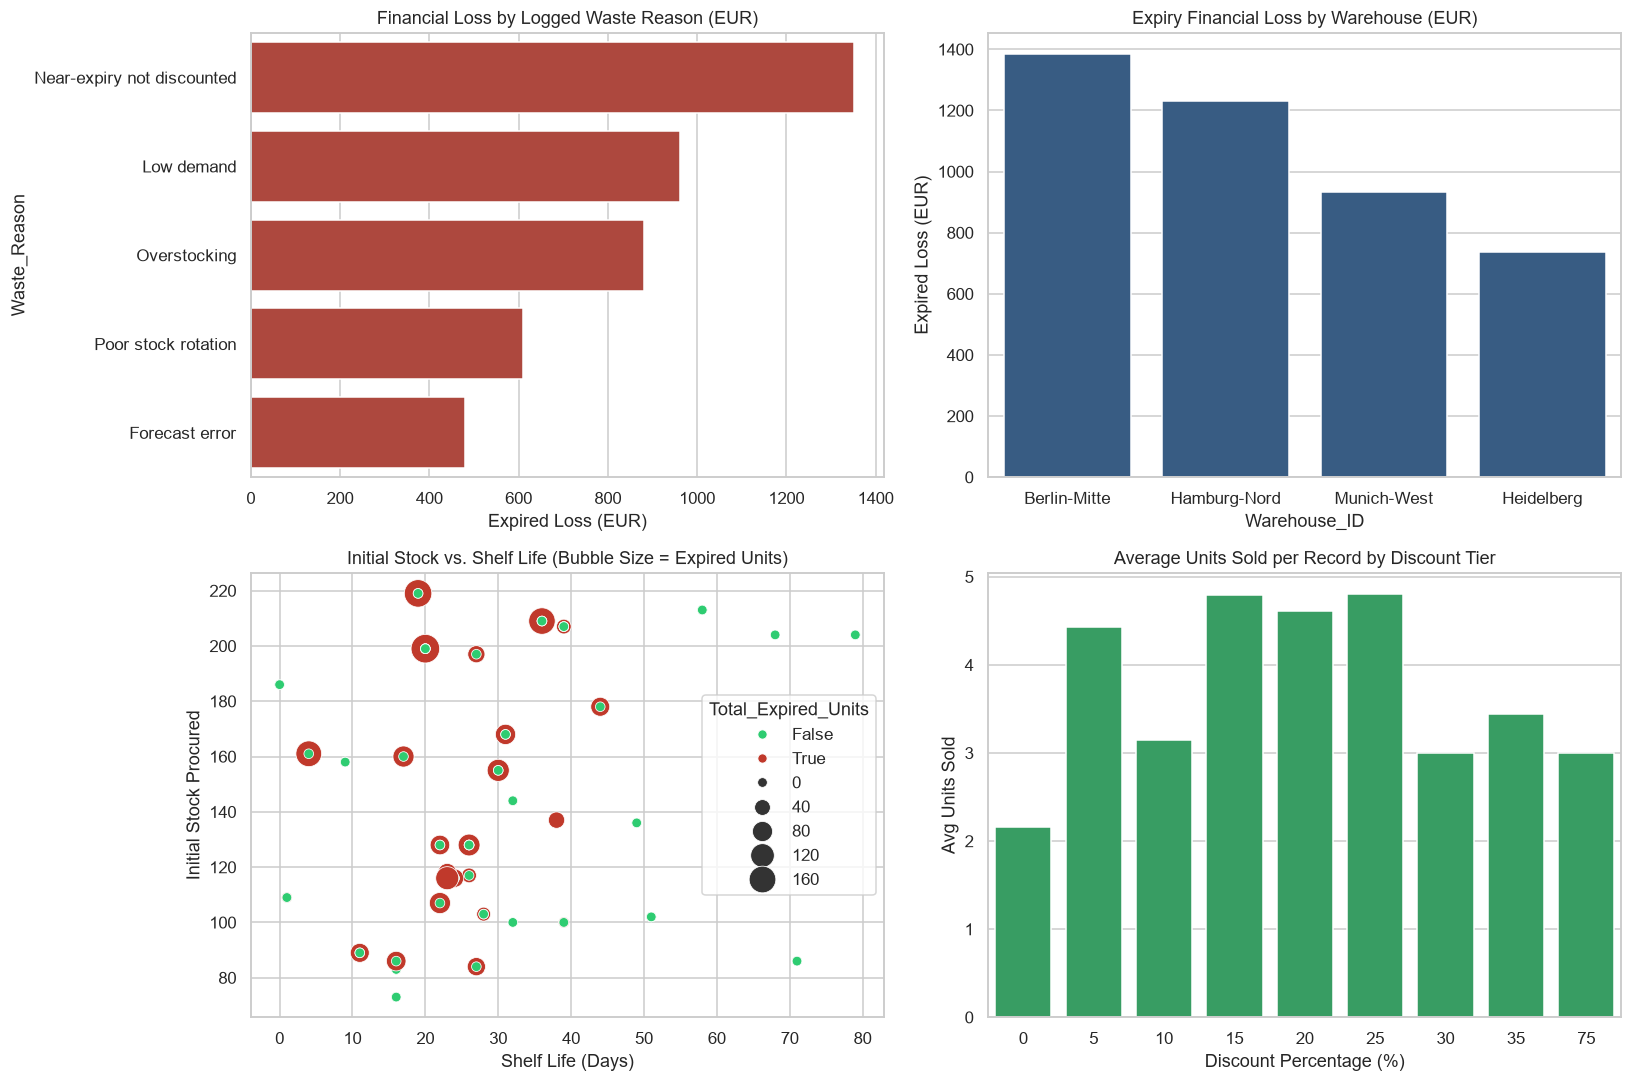

In [17]:
waste_events = eda_df[eda_df["Expired_Quantity"] > 0].copy()

waste_reason_summary = (
    waste_events.fillna({"Waste_Reason": "Unspecified"})
    .groupby("Waste_Reason", as_index=False)
    .agg(
        Affected_Batches=("Batch_ID", "nunique"),
        Waste_Events=("Product_ID", "count"),
        Total_Expired_Units=("Expired_Quantity", "sum"),
        Total_Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Avg_Discount_Applied=("Discount_Percentage", "mean")
    )
    .sort_values(by="Total_Expired_Loss_EUR", ascending=False)
)
waste_reason_summary["Loss_Share_Pct"] = (
    waste_reason_summary["Total_Expired_Loss_EUR"] / waste_reason_summary["Total_Expired_Loss_EUR"].sum() * 100
).round(2)

print("ROOT CAUSE 1: DOCUMENTED WASTE REASONS")
display(waste_reason_summary)

warehouse_summary = (
    batch_level_df.groupby("Warehouse_ID", dropna=False, as_index=False)
    .agg(
        Batches=("Batch_ID", "count"),
        Initial_Stock=("Initial_Stock", "sum"),
        Units_Sold=("Total_Units_Sold", "sum"),
        Expired_Units=("Total_Expired_Units", "sum"),
        Total_Revenue=("Total_Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Expired_Loss_EUR=("Expired_Loss_EUR", "sum"),
        Net_Profit_After_Waste=("Net_Profit_After_Waste", "sum"),
        Avg_Discount_Pct=("Avg_Discount_Pct", "mean")
    )
    .sort_values(by="Expired_Loss_EUR", ascending=False)
)
warehouse_summary["Expiry_Rate_Pct"] = (
    warehouse_summary["Expired_Units"] / warehouse_summary["Initial_Stock"] * 100
).round(2)
warehouse_summary["Sell_Through_Pct"] = (
    warehouse_summary["Units_Sold"] / warehouse_summary["Initial_Stock"] * 100
).round(2)

print("\nROOT CAUSE 2: WAREHOUSE EXPIRY & SELL-THROUGH COMPARISON")
display(warehouse_summary)

expired_batches = batch_level_df[batch_level_df["Total_Expired_Units"] > 0].sort_values(
    by="Expired_Loss_EUR", ascending=False
)

print("\nROOT CAUSE 3: BATCH-LEVEL INSPECTION OF ALL EXPIRED BATCHES")
display(expired_batches[[
    "Batch_ID", "Product_Name", "Category", "Warehouse_ID",
    "Shelf_Life_Days", "Initial_Stock", "Total_Units_Sold",
    "Total_Expired_Units", "Sell_Through_Rate_Pct", "Expiry_Waste_Rate_Pct",
    "Avg_Discount_Pct", "Max_Discount_Pct", "Expired_Loss_EUR", "Net_Profit_After_Waste"
]])

discount_impact = (
    eda_df.groupby("Discount_Percentage", as_index=False)
    .agg(
        Transactions=("Product_ID", "count"),
        Avg_Units_Sold_Per_Tx=("Quantity_Sold", "mean"),
        Total_Units_Sold=("Quantity_Sold", "sum"),
        Avg_Unit_Margin=("Unit_Margin", "mean"),
        Total_Gross_Profit=("Gross_Profit", "sum")
    )
    .sort_values(by="Discount_Percentage")
)

print("\nROOT CAUSE 4: SALES VELOCITY & UNIT MARGIN BY DISCOUNT TIER")
display(discount_impact)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.barplot(
    data=waste_reason_summary,
    x="Total_Expired_Loss_EUR",
    y="Waste_Reason",
    ax=axes[0, 0],
    color="#c0392b"
)
axes[0, 0].set_title("Financial Loss by Logged Waste Reason (EUR)")
axes[0, 0].set_xlabel("Expired Loss (EUR)")

sns.barplot(
    data=warehouse_summary.dropna(subset=["Warehouse_ID"]),
    x="Warehouse_ID",
    y="Expired_Loss_EUR",
    ax=axes[0, 1],
    color="#2b5c8f"
)
axes[0, 1].set_title("Expiry Financial Loss by Warehouse (EUR)")
axes[0, 1].set_ylabel("Expired Loss (EUR)")

sns.scatterplot(
    data=batch_level_df,
    x="Shelf_Life_Days",
    y="Initial_Stock",
    size="Total_Expired_Units",
    hue=batch_level_df["Total_Expired_Units"] > 0,
    sizes=(40, 350),
    palette={True: "#c0392b", False: "#2ecc71"},
    ax=axes[1, 0]
)
axes[1, 0].set_title("Initial Stock vs. Shelf Life (Bubble Size = Expired Units)")
axes[1, 0].set_xlabel("Shelf Life (Days)")
axes[1, 0].set_ylabel("Initial Stock Procured")

sns.barplot(
    data=discount_impact,
    x="Discount_Percentage",
    y="Avg_Units_Sold_Per_Tx",
    ax=axes[1, 1],
    color="#27ae60"
)
axes[1, 1].set_title("Average Units Sold per Record by Discount Tier")
axes[1, 1].set_xlabel("Discount Percentage (%)")
axes[1, 1].set_ylabel("Avg Units Sold")

plt.tight_layout()
plt.show()


## Step 19: Diagnostic Correlation & Sales-After-Expiry Audit


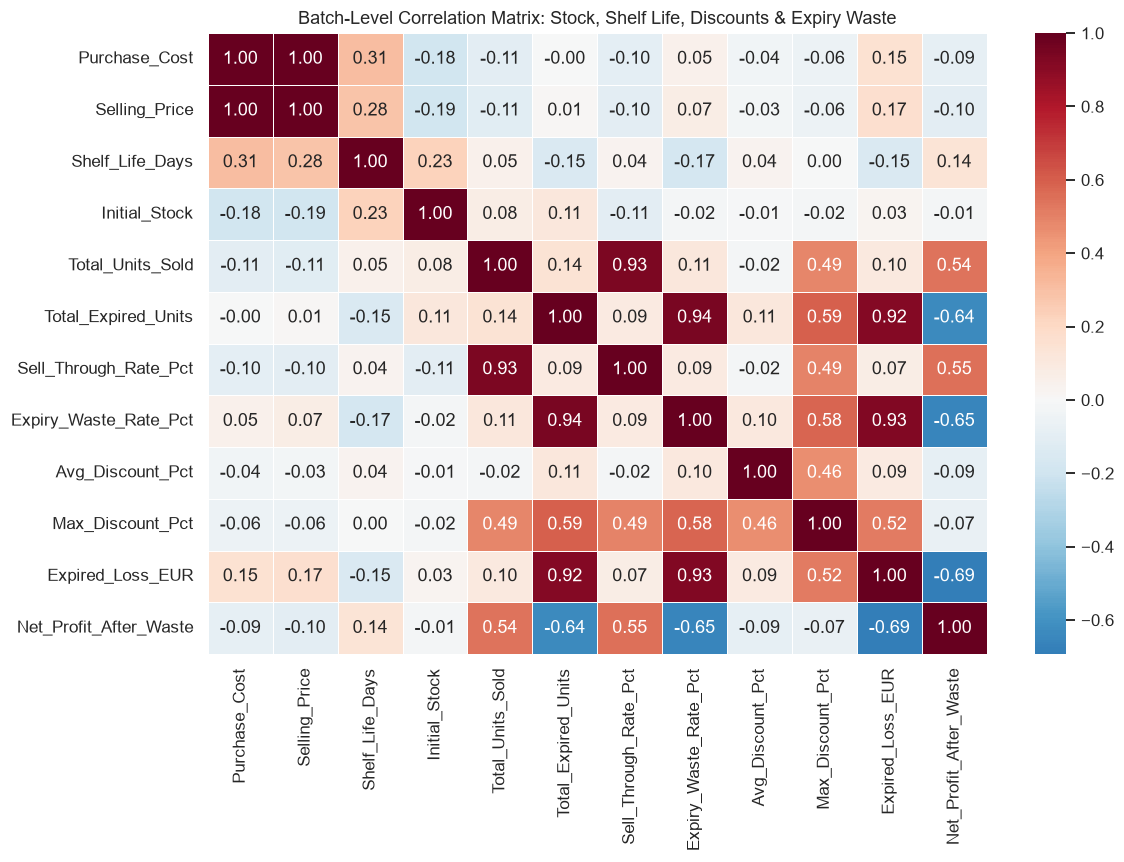

Post-Expiry Active Sales Records (Quantity_Sold > 0 after Expiry_Date): 95


,Product_Name,Warehouse_ID,Post_Expiry_Tx,Units_Sold_After_Expiry,Revenue_After_Expiry
1,Frozen Margherita Pizza,Heidelberg,23,187.0,839.63
0,Cheese Pizza Snacks,Berlin-Mitte,30,158.0,751.54
2,Spinach Portions,Munich-West,28,106.0,241.59
3,Vanilla Ice Cream,Munich-West,14,65.0,278.85


In [18]:
corr_cols = [
    "Purchase_Cost", "Selling_Price", "Shelf_Life_Days",
    "Initial_Stock", "Total_Units_Sold", "Total_Expired_Units",
    "Sell_Through_Rate_Pct", "Expiry_Waste_Rate_Pct",
    "Avg_Discount_Pct", "Max_Discount_Pct", "Expired_Loss_EUR", "Net_Profit_After_Waste"
]

corr_matrix = batch_level_df[corr_cols].corr().round(3)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Batch-Level Correlation Matrix: Stock, Shelf Life, Discounts & Expiry Waste")
plt.tight_layout()
plt.show()

post_expiry_sales = eda_df[(eda_df["Sale_After_Expiry"]) & (eda_df["Quantity_Sold"] > 0)]
print("Post-Expiry Active Sales Records (Quantity_Sold > 0 after Expiry_Date):", len(post_expiry_sales))
if len(post_expiry_sales) > 0:
    display(
        post_expiry_sales.groupby(["Product_Name", "Warehouse_ID"], as_index=False)
        .agg(
            Post_Expiry_Tx=("Product_ID", "count"),
            Units_Sold_After_Expiry=("Quantity_Sold", "sum"),
            Revenue_After_Expiry=("Total_Revenue", "sum")
        )
        .sort_values(by="Units_Sold_After_Expiry", ascending=False)
    )


## Step 20: Prescriptive Analysis & Strategy Simulation — Stock & Discount Recommendations


SKU-LEVEL STOCK & DISCOUNT OPTIMIZATION ROADMAP (AT-RISK PRODUCTS)


,Product_ID,Product_Name,Category,Expired_Units,Expired_Loss_EUR,Avg_Batch_Initial_Stock,Recommended_Batch_Cap,Recommended_Reorder_Policy,Recommended_Discount_Trigger,Avoided_Waste_Cost_EUR,Incremental_Markdown_Revenue_EUR,Total_Profit_Recovery_EUR
0,FP017,Frozen Shrimp,Seafood,188,770.80,101.0,9,Cut Batch Size & Split Deliveries,20% at T-7d | 40% at T-3d,766.70,13.31,780.01
1,FP008,Strawberry Ice Cream,Ice Cream,344,739.60,205.7,22,Cut Batch Size & Split Deliveries,15% at T-7d | 30% at T-3d,739.60,0.00,739.60
2,FP009,Frozen Lasagne,Ready Meals,238,642.60,134.0,15,Cut Batch Size & Split Deliveries,20% at T-7d | 40% at T-3d,642.60,0.00,642.60
3,FP012,Vegan Burger Patties,Plant Based,139,403.10,123.0,60,Cut Batch Size & Split Deliveries,20% at T-7d | 40% at T-3d,388.60,33.48,422.08
4,FP006,Frozen Fish Fingers,Seafood,131,366.80,146.7,52,Cut Batch Size & Split Deliveries,15% at T-7d | 30% at T-3d,366.80,0.00,366.80
5,FP015,Frozen Waffles,Breakfast,184,312.80,159.3,52,Cut Batch Size & Split Deliveries,15% at T-7d | 30% at T-3d,312.80,0.00,312.80
6,FP002,Frozen Pepperoni Pizza,Pizza,123,301.35,138.5,45,Cut Batch Size & Split Deliveries,20% at T-7d | 40% at T-3d,301.35,0.00,301.35
7,FP018,Spinach Portions,Vegetables,174,165.30,164.0,83,Cut Batch Size & Split Deliveries,20% at T-7d | 40% at T-3d,161.50,12.09,173.59
8,FP003,Frozen Mixed Vegetables,Frozen vegetables,99,118.80,128.0,12,Cut Batch Size & Split Deliveries,15% at T-7d | 30% at T-3d,118.80,0.00,118.80
9,FP014,Garlic Bread,Bakery,84,113.40,200.3,114,Cut Batch Size & Split Deliveries,15% at T-7d | 30% at T-3d,113.40,0.00,113.40



PROJECTED FINANCIAL IMPACT OF RECOMMENDED INTERVENTIONS


,Simulation_Metric,Value
0,Baseline Expired Units (October 2026),1913.00
1,Projected Expired Units After Intervention,33.00
2,Projected Waste Volume Reduction (%),98.27
3,Baseline Direct Expiry Loss (EUR),4284.60
4,Direct Waste Cost Avoided (EUR),4222.50
5,Incremental Near-Expiry Markdown Revenue (EUR),160.39
6,Total Projected Monthly Net Profit Improvement...,4382.89


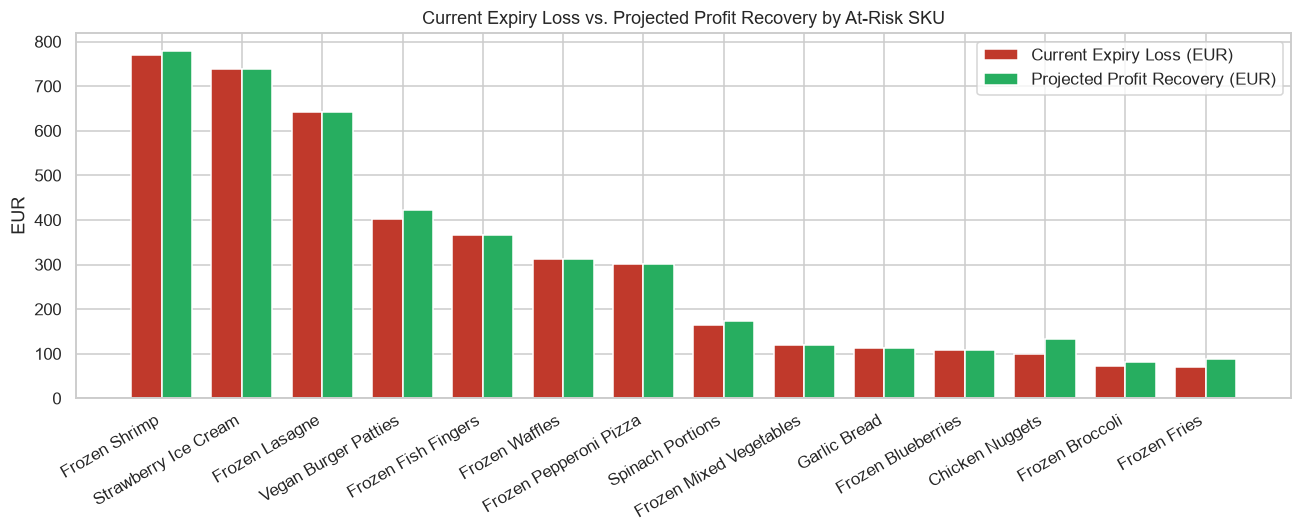

In [19]:
strategy_df = product_waste_summary.copy()

strategy_df["Avg_Batch_Demand"] = (strategy_df["Units_Sold"] / strategy_df["Batches"]).round(1)
strategy_df["Avg_Batch_Initial_Stock"] = (strategy_df["Initial_Stock"] / strategy_df["Batches"]).round(1)
strategy_df["Recommended_Batch_Cap"] = np.ceil(strategy_df["Avg_Batch_Demand"] * 1.20).astype(int)

strategy_df["Recommended_Reorder_Policy"] = np.where(
    strategy_df["Expiry_Rate_Pct"] > 10,
    "Cut Batch Size & Split Deliveries",
    np.where(
        strategy_df["Expiry_Rate_Pct"] > 0,
        "Cap Order at 1.2x Monthly Demand",
        "Maintain Current Par Level"
    )
)

strategy_df["Recommended_Discount_Trigger"] = np.where(
    strategy_df["Avg_Shelf_Life_Days"] <= 25,
    "20% at T-7d | 40% at T-3d",
    "15% at T-7d | 30% at T-3d"
)

at_risk_skus = strategy_df[strategy_df["Expired_Units"] > 0].copy()

at_risk_skus["Units_Saved_by_Stock_Cap"] = np.minimum(
    at_risk_skus["Expired_Units"],
    np.maximum(0, at_risk_skus["Initial_Stock"] - (at_risk_skus["Recommended_Batch_Cap"] * at_risk_skus["Batches"]))
)

remaining_after_cap = at_risk_skus["Expired_Units"] - at_risk_skus["Units_Saved_by_Stock_Cap"]
at_risk_skus["Units_Cleared_by_Markdown"] = np.round(remaining_after_cap * 0.65).astype(int)
at_risk_skus["Projected_Remaining_Waste"] = (
    at_risk_skus["Expired_Units"] - at_risk_skus["Units_Saved_by_Stock_Cap"] - at_risk_skus["Units_Cleared_by_Markdown"]
)

unit_cost = at_risk_skus["Expired_Loss_EUR"] / at_risk_skus["Expired_Units"]
avg_unit_price = at_risk_skus["Total_Revenue"] / at_risk_skus["Units_Sold"].replace(0, np.nan)
markdown_selling_price = avg_unit_price * 0.70

at_risk_skus["Avoided_Waste_Cost_EUR"] = (
    (at_risk_skus["Units_Saved_by_Stock_Cap"] + at_risk_skus["Units_Cleared_by_Markdown"]) * unit_cost
).round(2)
at_risk_skus["Incremental_Markdown_Revenue_EUR"] = (
    at_risk_skus["Units_Cleared_by_Markdown"] * markdown_selling_price
).round(2)
at_risk_skus["Total_Profit_Recovery_EUR"] = (
    at_risk_skus["Avoided_Waste_Cost_EUR"] + at_risk_skus["Incremental_Markdown_Revenue_EUR"]
).round(2)

print("SKU-LEVEL STOCK & DISCOUNT OPTIMIZATION ROADMAP (AT-RISK PRODUCTS)")
display(at_risk_skus[[
    "Product_ID", "Product_Name", "Category", "Expired_Units", "Expired_Loss_EUR",
    "Avg_Batch_Initial_Stock", "Recommended_Batch_Cap",
    "Recommended_Reorder_Policy", "Recommended_Discount_Trigger",
    "Avoided_Waste_Cost_EUR", "Incremental_Markdown_Revenue_EUR", "Total_Profit_Recovery_EUR"
]])

total_current_loss = round(at_risk_skus["Expired_Loss_EUR"].sum(), 2)
total_avoided_cost = round(at_risk_skus["Avoided_Waste_Cost_EUR"].sum(), 2)
total_markdown_rev = round(at_risk_skus["Incremental_Markdown_Revenue_EUR"].sum(), 2)
total_profit_gain = round(at_risk_skus["Total_Profit_Recovery_EUR"].sum(), 2)
waste_reduction_pct = round(
    (at_risk_skus["Units_Saved_by_Stock_Cap"].sum() + at_risk_skus["Units_Cleared_by_Markdown"].sum())
    / at_risk_skus["Expired_Units"].sum() * 100, 2
)

simulation_summary = pd.DataFrame({
    "Simulation_Metric": [
        "Baseline Expired Units (October 2026)",
        "Projected Expired Units After Intervention",
        "Projected Waste Volume Reduction (%)",
        "Baseline Direct Expiry Loss (EUR)",
        "Direct Waste Cost Avoided (EUR)",
        "Incremental Near-Expiry Markdown Revenue (EUR)",
        "Total Projected Monthly Net Profit Improvement (EUR)"
    ],
    "Value": [
        int(at_risk_skus["Expired_Units"].sum()),
        int(at_risk_skus["Projected_Remaining_Waste"].sum()),
        waste_reduction_pct,
        total_current_loss,
        total_avoided_cost,
        total_markdown_rev,
        total_profit_gain
    ]
})

print("\nPROJECTED FINANCIAL IMPACT OF RECOMMENDED INTERVENTIONS")
display(simulation_summary)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(at_risk_skus))
w = 0.38
ax.bar(x - w/2, at_risk_skus["Expired_Loss_EUR"], w, label="Current Expiry Loss (EUR)", color="#c0392b")
ax.bar(x + w/2, at_risk_skus["Total_Profit_Recovery_EUR"], w, label="Projected Profit Recovery (EUR)", color="#27ae60")
ax.set_xticks(x)
ax.set_xticklabels(at_risk_skus["Product_Name"], rotation=30, ha="right")
ax.set_title("Current Expiry Loss vs. Projected Profit Recovery by At-Risk SKU")
ax.set_ylabel("EUR")
ax.legend()
plt.tight_layout()
plt.show()


## Step 21: Export Data Analyst Deliverables


In [20]:
ANALYST_OUTPUT_FOLDER = Path("Flink_Analyst_Output")
ANALYST_OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

product_waste_summary.to_csv(ANALYST_OUTPUT_FOLDER / "Product_Waste_Ranking.csv", index=False)
warehouse_summary.to_csv(ANALYST_OUTPUT_FOLDER / "Warehouse_Performance_Summary.csv", index=False)
waste_reason_summary.to_csv(ANALYST_OUTPUT_FOLDER / "Waste_Root_Cause_Breakdown.csv", index=False)
at_risk_skus.to_csv(ANALYST_OUTPUT_FOLDER / "Stock_Discount_Recommendations.csv", index=False)

print("DATA ANALYST DELIVERABLES EXPORTED SUCCESSFULLY")
for file in ANALYST_OUTPUT_FOLDER.iterdir():
    print("-", file.name)


DATA ANALYST DELIVERABLES EXPORTED SUCCESSFULLY
- Product_Waste_Ranking.csv
- Stock_Discount_Recommendations.csv
- Warehouse_Performance_Summary.csv
- Waste_Root_Cause_Breakdown.csv
